# Power Analysis and Sample Size Planning

"How many participants do I need?" is the first question of every well-designed study — and the one most often skipped. An **underpowered** study wastes resources: it will probably miss a real effect, and if it does find one, it will exaggerate it. This lesson shows how to plan the sample size *before* collecting data.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. The Four Linked Quantities

A power analysis connects four quantities. Fix any three and the fourth is determined:

| Quantity | Meaning | Typical choice |
|---|---|---|
| significance level $\alpha$ | false-positive rate | 0.05 |
| **power** $1 - \beta$ | probability of detecting a true effect | 0.80 or 0.90 |
| **effect size** | the smallest effect worth detecting (e.g. Cohen's $d$, a difference in proportions) | from domain knowledge |
| **sample size** $n$ | observations per group | what we usually solve for |

For a two-sample t-test with equal group sizes, the approximate required size per group is

$$
n \approx \frac{2\,(z_{1-\alpha/2} + z_{1-\beta})^2}{d^2}
$$

so halving the effect size **quadruples** the required sample.

In [2]:
z_a <- qnorm(0.975); z_b <- qnorm(0.80)
for (d in c(0.8, 0.5, 0.2)) {
  approx_n <- 2 * (z_a + z_b)^2 / d^2
  exact_n  <- power.t.test(delta = d, sd = 1, power = 0.80, sig.level = 0.05)$n
  cat(sprintf("d = %.1f: formula n = %5.1f | power.t.test n = %5.1f per group\n", d, approx_n, exact_n))
}

d = 0.8: formula n =  24.5 | power.t.test n =  25.5 per group
d = 0.5: formula n =  62.8 | power.t.test n =  63.8 per group
d = 0.2: formula n = 392.4 | power.t.test n = 393.4 per group


## 2. Planning a Two-Group Study

A teacher wants to test whether a new study method raises exam scores. Past exams have $SD \approx 12$ points, and a gain of **5 points** would be worth adopting the method.

In [3]:
plan <- power.t.test(delta = 5, sd = 12, power = 0.80, sig.level = 0.05)
plan
cat("-> recruit", ceiling(plan$n), "students per group (", 2 * ceiling(plan$n), "in total)\n\n")

# With only 30 per group, what is the power, and what effect could we reliably detect?
cat("Power with n = 30 per group:", round(power.t.test(n = 30, delta = 5, sd = 12)$power, 3), "\n")
cat("Smallest difference detectable with 80% power and n = 30:",
    round(power.t.test(n = 30, sd = 12, power = 0.80)$delta, 2), "points\n")


     Two-sample t test power calculation 

              n = 91.38944
          delta = 5
             sd = 12
      sig.level = 0.05
          power = 0.8
    alternative = two.sided

NOTE: n is number in *each* group


-> recruit 92 students per group ( 184 in total)



Power with n = 30 per group: 0.355 


Smallest difference detectable with 80% power and n = 30: 8.83 points


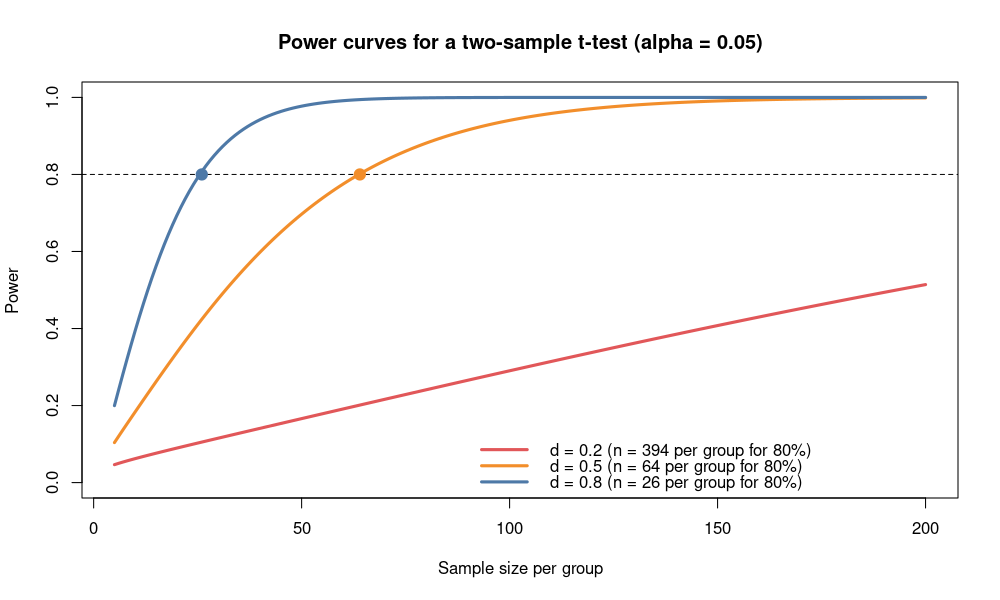

In [4]:
ns <- 5:200
d_values <- c(0.2, 0.5, 0.8)
cols <- c("#E15759", "#F28E2B", "#4E79A7")
plot(NA, xlim = range(ns), ylim = c(0, 1), main = "Power curves for a two-sample t-test (alpha = 0.05)",
     xlab = "Sample size per group", ylab = "Power")
for (i in seq_along(d_values))
  lines(ns, power.t.test(n = ns, delta = d_values[i], sd = 1)$power, lwd = 3, col = cols[i])
abline(h = 0.8, lty = 2)
needed <- sapply(d_values, function(d) ceiling(power.t.test(delta = d, sd = 1, power = 0.8)$n))
shown <- needed <= max(ns)   # d = 0.2 needs more than 200 per group - off the chart
points(needed[shown], rep(0.8, sum(shown)), pch = 19, cex = 1.5, col = cols[shown])
legend("bottomright", sprintf("d = %.1f (n = %d per group for 80%%)", d_values, needed), col = cols, lwd = 3, bty = "n")

## 3. Planning an A/B Test on Proportions

The current conversion rate is 10%. The team wants to detect an increase to 11% — a **minimum detectable effect (MDE)** of 1 percentage point.

In [5]:
ab_plan <- power.prop.test(p1 = 0.10, p2 = 0.11, power = 0.80, sig.level = 0.05)
ab_plan

mde <- c(0.005, 0.01, 0.02, 0.03)
needed <- sapply(mde, function(m) ceiling(power.prop.test(p1 = 0.10, p2 = 0.10 + m, power = 0.8)$n))
print(data.frame(baseline = "10%", MDE_pp = 100 * mde, visitors_per_group = needed, total = 2 * needed), row.names = FALSE)


     Two-sample comparison of proportions power calculation 

              n = 14750.79
             p1 = 0.1
             p2 = 0.11
      sig.level = 0.05
          power = 0.8
    alternative = two.sided

NOTE: n is number in *each* group


 baseline MDE_pp visitors_per_group  total
      10%    0.5              57763 115526
      10%    1.0              14751  29502
      10%    2.0               3841   7682
      10%    3.0               1774   3548


*Insight: Detecting a 1-point lift on a 10% baseline needs about 15,000 visitors **per group**. Small websites often can't run such tests at all. They need bigger changes, more traffic, or a metric with less noise.*

## 4. ANOVA and Simulation-based Power

`power.anova.test()` handles one-way ANOVA. For any other test — non-parametric, skewed data, complex designs — **simulate**: generate data under your assumed effect many times, run the planned test, and count how often it rejects.


     Balanced one-way analysis of variance power calculation 

         groups = 3
              n = 54.53712
    between.var = 9
     within.var = 100
      sig.level = 0.05
          power = 0.8

NOTE: n is number in each group


 n_per_group simulated_power
          10          0.1270
          20          0.2710
          30          0.3555
          40          0.4575
          60          0.6320
          80          0.7335


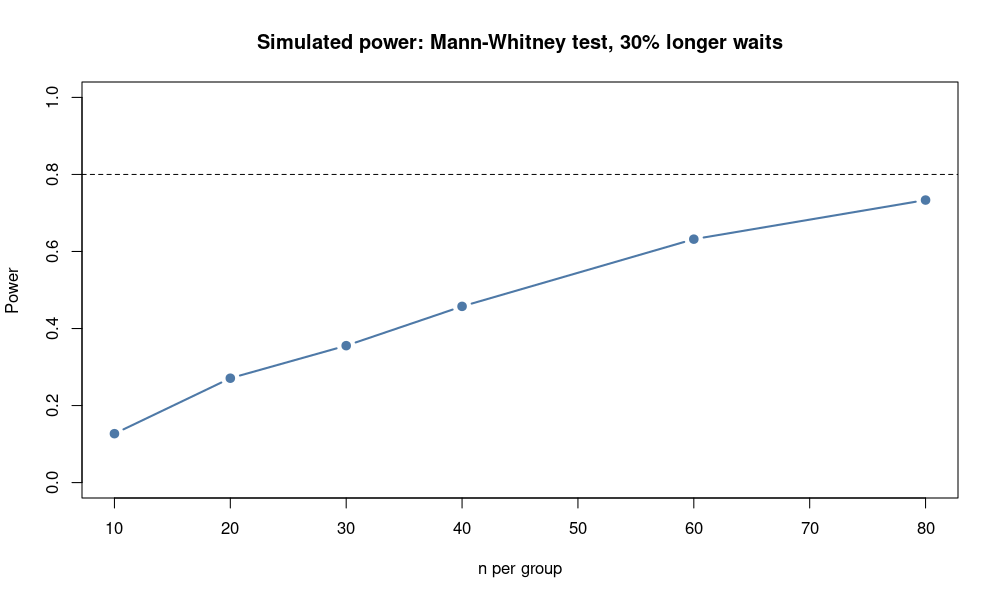

In [6]:
power.anova.test(groups = 3, between.var = var(c(50, 53, 56)), within.var = 10^2, power = 0.80)

# Simulation: Mann-Whitney test on skewed (log-normal) waiting times, 30% longer in group B
sim_power <- function(n, reps = 2000) {
  mean(replicate(reps, {
    a <- rlnorm(n, meanlog = log(5), sdlog = 0.6)
    b <- rlnorm(n, meanlog = log(5 * 1.3), sdlog = 0.6)
    wilcox.test(a, b, exact = FALSE)$p.value < 0.05
  }))
}
set.seed(20)
ns <- c(10, 20, 30, 40, 60, 80)
pw <- sapply(ns, sim_power)
print(data.frame(n_per_group = ns, simulated_power = pw), row.names = FALSE)
plot(ns, pw, type = "b", pch = 19, lwd = 2, col = "#4E79A7", ylim = c(0, 1),
     main = "Simulated power: Mann-Whitney test, 30% longer waits", xlab = "n per group", ylab = "Power")
abline(h = 0.8, lty = 2)

## 5. Why Underpowered Studies Mislead: the Winner's Curse

When power is low, only studies that happened to observe an unusually **large** effect cross the significance threshold. So the significant results from small studies **systematically overestimate** the true effect.

 n_per_group power mean_estimate_all mean_estimate_significant_only
          20 0.153             0.296                          0.771
         200 0.849             0.298                          0.326


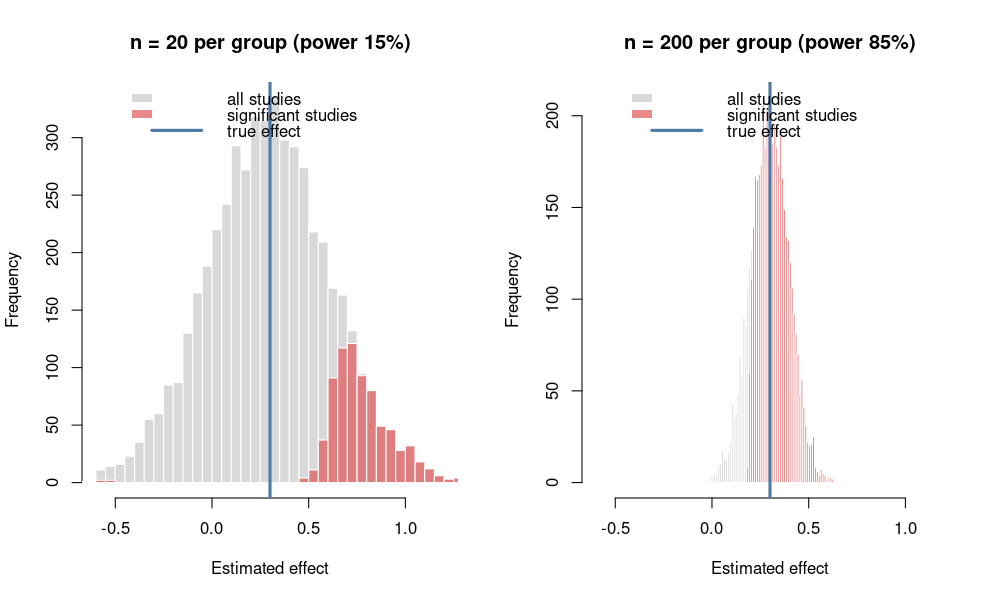

In [7]:
set.seed(2020)
true_d <- 0.3
run_studies <- function(n, reps = 5000) {
  t(replicate(reps, {
    x <- rnorm(n); y <- rnorm(n, mean = true_d)
    c(d_hat = mean(y) - mean(x), sig = t.test(y, x)$p.value < 0.05)
  }))
}
small <- run_studies(20); large <- run_studies(200)

summ <- data.frame(
  n_per_group = c(20, 200),
  power = c(mean(small[, "sig"]), mean(large[, "sig"])),
  mean_estimate_all = c(mean(small[, "d_hat"]), mean(large[, "d_hat"])),
  mean_estimate_significant_only = c(mean(small[small[, "sig"] == 1, "d_hat"]), mean(large[large[, "sig"] == 1, "d_hat"]))
)
print(round(summ, 3), row.names = FALSE)

par(mfrow = c(1, 2))
for (res in list(list(small, 20), list(large, 200))) {
  r <- res[[1]]
  hist(r[, "d_hat"], breaks = 50, col = "grey85", border = "white", xlim = c(-0.6, 1.2),
       main = sprintf("n = %d per group (power %.0f%%)", res[[2]], 100 * mean(r[, "sig"])), xlab = "Estimated effect")
  hist(r[r[, "sig"] == 1, "d_hat"], breaks = 50, col = adjustcolor("#E15759", 0.7), border = "white", add = TRUE)
  abline(v = true_d, lwd = 3, col = "#4E79A7")
  legend("topright", c("all studies", "significant studies", "true effect"), bty = "n",
         fill = c("grey85", adjustcolor("#E15759", 0.7), NA), border = NA, lty = c(NA, NA, 1), lwd = c(NA, NA, 3),
         col = c(NA, NA, "#4E79A7"))
}

*Insight: With 20 per group, the significant studies report an effect about 2.5 times the true one (0.77 vs 0.30), while with 200 per group they are close to the truth. This is a big reason why striking findings from small studies often shrink or vanish when they are replicated. Plan for adequate power, and be sceptical of large effects from small samples.*

## 6. Practical Checklist

1. Define the **primary outcome** and the test you will use.
2. Choose the **smallest effect that matters** in practice (not the effect you hope for), and an estimate of variability from past data.
3. Pick $\alpha$ (usually 0.05) and power (0.80–0.90).
4. Compute $n$, then add a margin for dropouts (e.g. +10–15%).
5. Write the plan down **before** collecting data (pre-registration, Lesson 13), and don't stop early just because $p < 0.05$.

**Post-hoc ("observed") power**, computed from the effect you just observed, adds no information beyond the p-value. Power is a **planning** tool.

## Real-World Use Case or Analogy

Power is like the **magnification of a telescope**. A faint, distant star (a small effect) needs a big telescope (a large sample). Point a small telescope at it and you'll usually see nothing. On the rare nights you do "see" it, the image is distorted and looks brighter than the star really is: that's the winner's curse.

- **Clinical trials** must justify their sample size to ethics committees: too few patients is unethical (they bear risk for an inconclusive study), and so is too many (more people exposed than necessary).
- **Product teams** use A/B test calculators, which are exactly `power.prop.test()`, to decide how long an experiment must run.